# Free fall with PINNs: direct and inverse problem

We drop a ball from different heights and measure the time it takes to reach the floor. The position (height) of the ball $u(t)$ obeys Newton's second law

$$u''(t) + \frac{\partial V(u)}{\partial u} = 0 \qquad ; \qquad {}' \equiv \frac{d}{dt}$$

where $V(u)$ is the potential (per unit mass). For a uniform gravitational field, $V(u) = g\,u$ with $g = 9.81\ \mathrm{m/s^2}$, so that $u'' = -g$.

We will do two things:

1. **Direct problem.** We *know* $V(u)$. Given the initial conditions $u_i(0) = u_{0,i}$ and $u_i'(0) = v_{0,i}$, we solve the ODE and extract the "boundary" information: the time of arrival to the floor $t_{f,i}$, defined by $u_i(t_{f,i}) = 0$. We do it numerically, and with a PINN.

2. **Inverse problem.** We *do not know* $V(u)$. We only have the data pairs $\{u_{0,i},\, t_{f,i}\}_{i=1}^{N}$, and we want to find the potential $V(u)$ that is compatible with all of them. We use two NNs, one for the solutions $u_i(t)$ and one for the potential $V(u)$, trained simultaneously from the same loss.

### Note on notation
As in the lecture notes, the PINN is trained by minimizing the residual of the differential equation, evaluated on the NN solution $\tilde u^\text{NN}$:

$$R(t) \equiv \left(\tilde u^\text{NN}(t)\right)'' + \frac{\partial V(u)}{\partial u}\bigg|_{u = \tilde u^\text{NN}(t)}$$

$$L_\text{DE} = \frac{1}{N N_t}\sum_{i=1}^{N} \sum_{k=1}^{N_t} \big( R\left[u_i(t_k)\right] \big)^2$$

where $i$ labels the initial conditions (the **bundle**) and $k$ the sampled times.

### Import the needed packages

In [1]:
import copy
import os
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from tqdm.autonotebook import trange

torch.manual_seed(0)

/var/folders/2p/n54j77_93591_v0j0l16sbjw0000gn/T/ipykernel_19050/1778822451.py:7: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import trange


## 1. The physical problem

We define the potential and the set of initial conditions. The initial velocities default to zero (the ball is *dropped*), but they can be changed.

If you change the potential, change both `V_true` and its derivative `dVdu_true`.

In [69]:
g = 10          # m/s^2
nu = 4
A = 5
epsilon = 1

def V_true(u):
    if isinstance(u, torch.Tensor):
        return g * u + A/(u+epsilon )
    else:
        return g * u + A/(u +epsilon)

def dVdu_true(u):
    if isinstance(u, torch.Tensor):
        return g - A/(u +epsilon)**2
    else:
        return g - A/(u +epsilon)**2

N = 20                                   # number of initial conditions
u0_data = np.linspace(0.25, 5, N)       # initial heights u_i(0), in m
v0_data = np.zeros(N) #np.random.uniform(0, 5, N)    # initial velocities u_i'(0), in m/s

In [71]:
V_true(0)

5.0

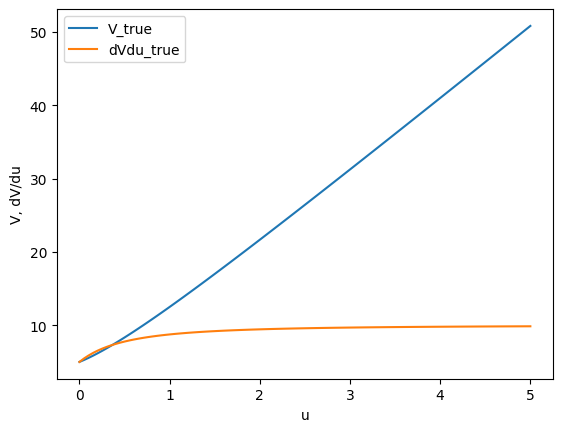

In [70]:
u_mock = np.linspace(0, 5, 100)
plt.plot(u_mock, V_true(u_mock), label='V_true')
plt.plot(u_mock, dVdu_true(u_mock), label='dVdu_true')
plt.xlabel('u')
plt.ylabel('V, dV/du')
plt.legend()
plt.show()

In [26]:
# import sympy as sp

# g = 9.81                                  # m/s^2

# def V_true(u):                            # potential (per unit mass)
#     return g * u + (2/3) * u**3 + sp.sin(0.5*u) + sp.log(u + 1)

# u_sym = sp.Symbol('u')
# dVdu_sym = sp.diff(V_true(u_sym), u_sym)  # analytic derivative of V_true
# dVdu_fn = sp.lambdify(u_sym, dVdu_sym)
# print('dV/du =', dVdu_sym)

# def dVdu_true(u):                         # its derivative
#     return dVdu_fn(u) + 0 * u

# N = 10                                    # number of initial conditions
# u0_data = np.linspace(0.25, 5, N)         # initial heights u_i(0), in m
# v0_data = np.zeros(N)                     # initial velocities u_i'(0), in m/s

## 2. Direct problem, numerically: generating the data

We write the ODE as a first order system, $u' = v$ and $v' = -\partial V/\partial u$, and integrate it with a 4th order Runge-Kutta method until the ball crosses the floor ($u = 0$). The arrival time $t_f$ is obtained by linear interpolation between the last two steps.

In [27]:
def solve_numerically(u0, v0, dt=1e-3):
    a = lambda u: -dVdu_true(u)           # acceleration
    t, u, v = 0.0, u0, v0
    ts, us = [t], [u]
    while u > 0:
        k1u, k1v = v, a(u)
        k2u, k2v = v + dt/2 * k1v, a(u + dt/2 * k1u)
        k3u, k3v = v + dt/2 * k2v, a(u + dt/2 * k2u)
        k4u, k4v = v + dt * k3v, a(u + dt * k3u)
        u += dt/6 * (k1u + 2*k2u + 2*k3u + k4u)
        v += dt/6 * (k1v + 2*k2v + 2*k3v + k4v)
        t += dt
        ts.append(t); us.append(u)
    tf = ts[-2] + dt * us[-2] / (us[-2] - us[-1])   # floor crossing
    return np.array(ts), np.array(us), tf

In [28]:
numerical = [solve_numerically(u0, v0) for u0, v0 in zip(u0_data, v0_data)]
tf_data = np.array([tf for _, _, tf in numerical])

for u0, tf in zip(u0_data, tf_data):
    print(f'u0 = {u0:.2f} m   ->   tf = {tf:.4f} s')

u0 = 0.25 m   ->   tf = 0.2763 s
u0 = 0.50 m   ->   tf = 0.3662 s
u0 = 0.75 m   ->   tf = 0.4321 s
u0 = 1.00 m   ->   tf = 0.4870 s
u0 = 1.25 m   ->   tf = 0.5356 s
u0 = 1.50 m   ->   tf = 0.5797 s
u0 = 1.75 m   ->   tf = 0.6206 s
u0 = 2.00 m   ->   tf = 0.6589 s
u0 = 2.25 m   ->   tf = 0.6950 s
u0 = 2.50 m   ->   tf = 0.7294 s
u0 = 2.75 m   ->   tf = 0.7623 s
u0 = 3.00 m   ->   tf = 0.7938 s
u0 = 3.25 m   ->   tf = 0.8242 s
u0 = 3.50 m   ->   tf = 0.8535 s
u0 = 3.75 m   ->   tf = 0.8818 s
u0 = 4.00 m   ->   tf = 0.9093 s
u0 = 4.25 m   ->   tf = 0.9360 s
u0 = 4.50 m   ->   tf = 0.9620 s
u0 = 4.75 m   ->   tf = 0.9873 s
u0 = 5.00 m   ->   tf = 1.0120 s


These pairs $\{u_{0,i},\, t_{f,i}\}$ are the "boundary" data. It is all the information that the inverse problem will be allowed to use.

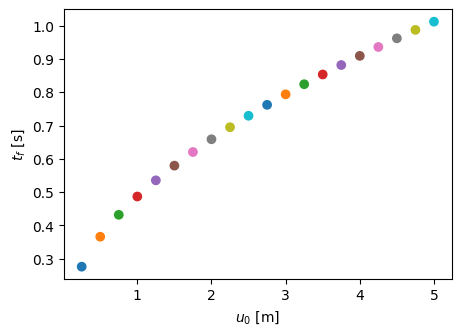

In [29]:
plt.figure(figsize=(5, 3.5))
plt.scatter(u0_data, tf_data, c=[f'C{i}' for i in range(N)])
plt.xlabel('$u_0$ [m]')
plt.ylabel('$t_f$ [s]')
plt.show()

## 3. Building blocks of the PINN

These are common to the direct and the inverse problem.

### The neural network
A simple Fully Connected Neural Network (FCNN). We choose the number of inputs and outputs, the hidden layers and the activation function.

In [30]:
class FCNN(nn.Module):
    def __init__(self, n_input, n_output, hidden=(32, 32, 32), actv=nn.Tanh):
        super().__init__()
        layers = []
        for h in hidden:
            layers += [nn.Linear(n_input, h), actv()]
            n_input = h
        self.NN = nn.Sequential(*layers, nn.Linear(n_input, n_output))

    def forward(self, *inputs):
        return self.NN(torch.cat(inputs, dim=1))

### Derivatives
The derivatives appearing in the residual are computed exactly with automatic differentiation.

In [31]:
def diff(y, x, order=1):
    for _ in range(order):
        y = torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]
    return y

### The solver
The solver is in charge of the training. A *problem* is a function that takes the NNs and the training points, and returns the solution $\tilde u^\text{NN}$ and the residual $R$ at those points. At every epoch the solver:

1. evaluates the residuals and the loss $L_\text{DE}$ (mean of the squared residuals),
2. keeps a copy of the NNs if the loss is the best one so far,
3. computes the gradient of the loss and updates the parameters (optimizer) and the learning rate (scheduler).

Calling `fit` again continues the training where it was left.

In [32]:
class Solver:
    def __init__(self, problem, nets, optimizer, scheduler, points):
        self.problem, self.nets, self.points = problem, nets, points
        self.optimizer, self.scheduler = optimizer, scheduler
        self.loss_history = []
        self.best_loss, self.best_nets = float('inf'), copy.deepcopy(nets)

    def fit(self, epochs):
        bar = trange(epochs)
        for epoch in bar:
            self.optimizer.zero_grad()
            u, R = self.problem(self.nets, *self.points)
            loss = (R**2).mean()
            if loss.item() < self.best_loss:
                self.best_loss, self.best_nets = loss.item(), copy.deepcopy(self.nets)
            loss.backward()
            self.optimizer.step()
            self.scheduler.step()
            self.loss_history.append(loss.item())
            bar.set_postfix(loss=f'{loss.item():.3e}', best=f'{self.best_loss:.3e}')

### Save and load a model
`save_model` stores the parameters of the NNs (current and best), the state of the optimizer and scheduler, and the loss history. `load_model` loads them into a solver that has been created with the same architecture, to visualize results or to keep on training.

In [33]:
def save_model(solver, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({'nets': [net.state_dict() for net in solver.nets],
                'best_nets': [net.state_dict() for net in solver.best_nets],
                'optimizer': solver.optimizer.state_dict(),
                'scheduler': solver.scheduler.state_dict(),
                'loss_history': solver.loss_history,
                'best_loss': solver.best_loss}, path)
    print(f'Model saved in {path}')

def load_model(solver, path):
    state = torch.load(path)
    for net, best_net, s, s_best in zip(solver.nets, solver.best_nets, state['nets'], state['best_nets']):
        net.load_state_dict(s)
        best_net.load_state_dict(s_best)
    solver.optimizer.load_state_dict(state['optimizer'])
    solver.scheduler.load_state_dict(state['scheduler'])
    solver.loss_history, solver.best_loss = state['loss_history'], state['best_loss']
    print(f'Model loaded from {path}')

### Training points
We sample $N_t$ equally spaced times for each of the $N$ initial conditions. All tensors are columns with one row per pair $(i, k)$, so that the whole bundle is evaluated at once.

- Direct problem: all trajectories are sampled in the same interval $t \in [0, \max_i t_{f,i}]$.
- Inverse problem: each trajectory is sampled between its two boundaries, $t \in [0, t_{f,i}]$.

In [34]:
N_t = 64                                  # number of times per initial condition

column = lambda x: torch.tensor(x, dtype=torch.float32).repeat_interleave(N_t).reshape(-1, 1)
u0, v0, tf = column(u0_data), column(v0_data), column(tf_data)

s = torch.linspace(0, 1, N_t).repeat(N).reshape(-1, 1)
t_direct = (s * tf_data.max()).requires_grad_()
t_inverse = (s * tf).requires_grad_()

to_plot = lambda x: x.detach().reshape(N, N_t).numpy()      # one row per initial condition

## 4. Direct problem with a PINN

The potential is known, $V(u) = g\,u$, and we look for the solutions $u_i(t)$ for all the initial conditions at once.

### Model definition
We solve in a **bundle**: a single NN takes as inputs the time $t$ and the initial conditions $(u_0, v_0)$, and gives one output, $u^\text{NN}(t, u_0, v_0)$.

The initial conditions are imposed by construction (**hard enforcing**) through the reparametrization

$$\tilde u^\text{NN}(t) = u_0 + \left(1 - e^{-t}\right) v_0 + \left(1 - e^{-t}\right)^2\, u^\text{NN}(t, u_0, v_0)$$

One can check that $\tilde u^\text{NN}(0) = u_0$ and $(\tilde u^\text{NN})'(0) = v_0$. This way the only term in the loss is the DE residual.

In [35]:
def D(t):
    return 1 - torch.exp(-t)

def direct_problem(nets, t, u0, v0):
    u = u0 + D(t) * v0 + D(t)**2 * nets[0](t, u0, v0)       # reparametrization
    R = diff(u, t, order=2) + diff(V_true(u), u)            # residual of the ODE
    return u, R

In [36]:
nets_direct = [FCNN(n_input=3, n_output=1)]

### Optimizer

In [37]:
optimizer_direct = torch.optim.Adam(nets_direct[0].parameters(), lr=3e-3)

### Scheduler
It lowers the learning rate of Adam by a factor `gamma` every `step_size` epochs.

In [38]:
scheduler_direct = torch.optim.lr_scheduler.StepLR(optimizer_direct, step_size=2000, gamma=0.7)

### Solver

In [39]:
solver_direct = Solver(direct_problem, nets_direct, optimizer_direct, scheduler_direct,
                       points=(t_direct, u0, v0))

### (Optional) Load a pretrained model

In [40]:
# load_model(solver_direct, 'results/direct_problem.pt')

### Train the net
Choose the budget of epochs. To keep on training, just run this cell again.

In [41]:
epochs = 6000

solver_direct.fit(epochs)

100%|██████████| 6000/6000 [00:31<00:00, 190.72it/s, best=1.393e+00, loss=1.473e+00]


### Visualize the results

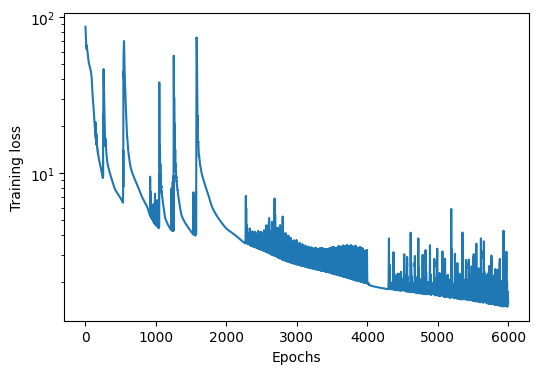

In [44]:
plt.figure(figsize=(6, 4))
plt.plot(solver_direct.loss_history)
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('Training loss')
plt.show()

#### Trajectories
Numerical solution (thick lines) and PINN solution at the best loss (dashed lines). Note that the PINN does not know about the floor, so its solutions just continue below $u = 0$.

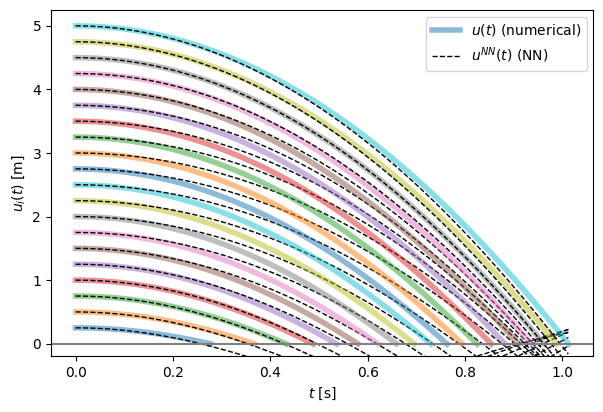

In [45]:
u_NN, R_NN = direct_problem(solver_direct.best_nets, t_direct, u0, v0)
t_plot, u_NN, R_NN = to_plot(t_direct), to_plot(u_NN), to_plot(R_NN)

plt.figure(figsize=(7, 4.5))
for i in range(N):
    if i==0:
        plt.plot(numerical[i][0], numerical[i][1], color=f'C{i}', lw=4, alpha=0.5, label=f'$u(t)$ (numerical)')
        plt.plot(t_plot[i], u_NN[i], 'k--', lw=1, label=f'$u^{{NN}}(t)$ (NN)')
    else:
        plt.plot(numerical[i][0], numerical[i][1], color=f'C{i}', lw=4, alpha=0.5)
        plt.plot(t_plot[i], u_NN[i], 'k--', lw=1)
plt.axhline(0, color='gray')
plt.ylim(-0.2, 1.05 * u_NN.max())
plt.xlabel('$t$ [s]')
plt.ylabel('$u_i(t)$ [m]')
plt.legend()
plt.show()

#### Residuals of the ODE
At the best loss, for all the initial conditions.

In [46]:
t_direct.shape

torch.Size([1280, 1])

In [47]:
u0[0].shape

torch.Size([1])

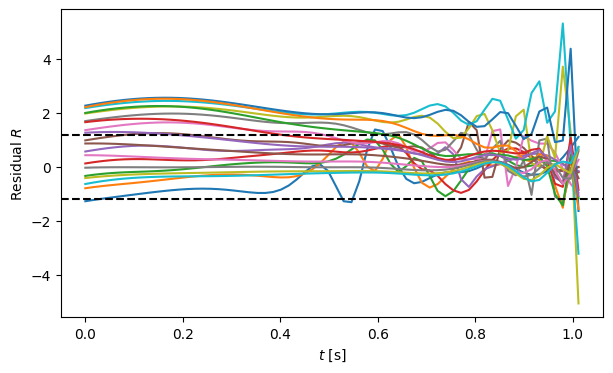

In [48]:
plt.figure(figsize=(7, 4))
for i in range(N):
    plt.plot(t_plot[i], R_NN[i], color=f'C{i}')
plt.axhline(np.sqrt(min(solver_direct.loss_history)), color='k', linestyle='--')
plt.axhline(-np.sqrt(min(solver_direct.loss_history)), color='k', linestyle='--')
plt.xlabel('$t$ [s]')
plt.ylabel('Residual $R$')
plt.show()

### Save the model (optional)

In [49]:
# save_model(solver_direct, 'results/direct_problem.pt')

## 5. Inverse problem with PINNs

Now we forget about the potential. We only keep the data pairs $\{u_{0,i},\, t_{f,i}\}_{i=1}^{N}$ (and the initial velocities), and we look for the $V(u)$ that allows for solutions of the ODE for all of them.

### Model definition
We use **two NNs**:

- $t,\, u_0,\, v_0,\, t_f \;\rightarrow\; \text{NN}_1 \;\rightarrow\; u^\text{NN}(t)$: the solutions in a bundle, as before. The boundary data $t_f$ is now an additional input.
- $u \;\rightarrow\; \text{NN}_2 \;\rightarrow\; V^\text{NN}(u)$: the unknown potential. Its input is the output of the first one, i.e. all the points $\tilde u_i^\text{NN}(t_k)$.

The data enters through the reparametrization, which now imposes by construction the initial conditions **and** the arrival to the floor at $t_f$:

$$\tilde u^\text{NN}(t) = \left[u_0 + \left(1 - e^{-t}\right) v_0\right] \left[1 - \frac{\left(1 - e^{-t}\right)^2}{\left(1 - e^{-t_f}\right)^2}\right] + \left(1 - e^{-t}\right)^2 \left(1 - e^{-(t_f - t)}\right) u^\text{NN}(t, u_0, v_0, t_f)$$

One can check that $\tilde u^\text{NN}(0) = u_0$, $(\tilde u^\text{NN})'(0) = v_0$ and $\tilde u^\text{NN}(t_f) = 0$.

The residual is the same as before, replacing the known potential by the second NN:

$$R = \left(\tilde u^\text{NN}(t)\right)'' + \frac{\partial V^\text{NN}(u)}{\partial u}\bigg|_{u = \tilde u^\text{NN}(t)}$$

In [50]:
def inverse_problem(nets, t, u0, v0, tf):
    u = (u0 + D(t) * v0) * (1 - D(t)**2 / D(tf)**2) + D(t)**2 * D(tf - t) * nets[0](t, u0, v0, tf)
    V = nets[1](u)                                          # potential from the second NN
    R = diff(u, t, order=2) + diff(V, u)                    # residual of the ODE
    return u, R

In [51]:
nets_inverse = [FCNN(n_input=4, n_output=1),    # NN_1: solutions u(t)
                FCNN(n_input=1, n_output=1)]    # NN_2: potential V(u)

### Optimizer
A single optimizer updates the parameters of both NNs, $W_D$ and $W_V$, with the gradients $\nabla_{W_D} L$ and $\nabla_{W_V} L$ of the same loss.

In [52]:
optimizer_inverse = torch.optim.Adam([p for net in nets_inverse for p in net.parameters()], lr=3e-3)

### Scheduler

In [53]:
scheduler_inverse = torch.optim.lr_scheduler.StepLR(optimizer_inverse, step_size=2000, gamma=0.7)

### Solver

In [54]:
solver_inverse = Solver(inverse_problem, nets_inverse, optimizer_inverse, scheduler_inverse,
                        points=(t_inverse, u0, v0, tf))

### (Optional) Load a pretrained model

In [55]:
# load_model(solver_inverse, 'results/inverse_problem.pt')

### Train the nets
Choose the budget of epochs. To keep on training, just run this cell again.

In [ ]:
optimizer_inverse.param_groups[0]['lr']

In [61]:
epochs = 6000

solver_inverse.fit(epochs)

100%|██████████| 6000/6000 [00:43<00:00, 137.68it/s, best=2.437e-05, loss=2.438e-05]


### Visualize the results

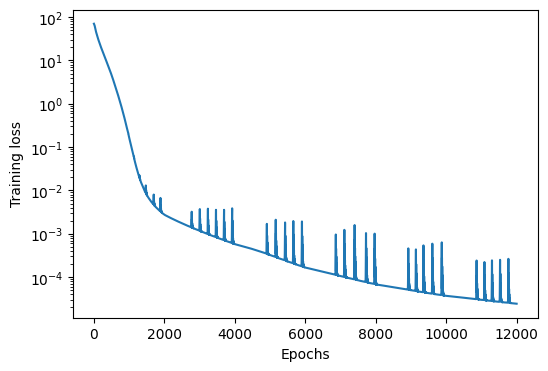

In [62]:
plt.figure(figsize=(6, 4))
plt.plot(solver_inverse.loss_history)
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('Training loss')
plt.show()

#### Recovered potential
The potential $V^\text{NN}(u)$ at the best loss, compared with the true one. Two remarks:

- Only $\partial V/\partial u$ appears in the ODE, so $V$ is determined up to a constant. We fix it by plotting $V^\text{NN}(u) - V^\text{NN}(0)$.
- The potential can only be recovered in the region explored by the data, $u \in [0, \max_i u_{0,i}]$.

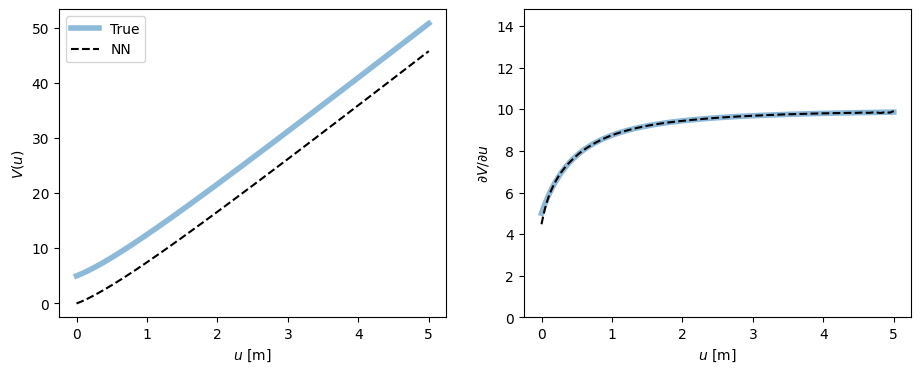

Mean val. of dV/du = 9.151075


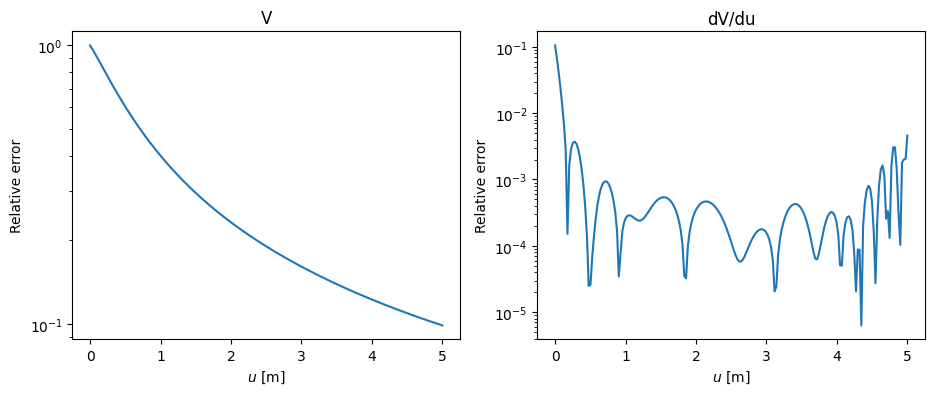

In [63]:
u_plot = torch.linspace(0, u0_data.max(), 200).reshape(-1, 1).requires_grad_()
V_NN = solver_inverse.best_nets[1](u_plot)
dVdu_NN = diff(V_NN, u_plot)
u_plot, V_NN, dVdu_NN = [x.detach().numpy().flatten() for x in (u_plot, V_NN - V_NN[0], dVdu_NN)]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(u_plot, V_true(u_plot), lw=4, alpha=0.5, label='True')
ax[0].plot(u_plot, V_NN, 'k--', label='NN')
ax[1].plot(u_plot, dVdu_true(u_plot), lw=4, alpha=0.5)
ax[1].plot(u_plot, dVdu_NN, 'k--')
ax[1].set_ylim(0, 1.5 * dVdu_true(u_plot).max())
ax[0].set(xlabel='$u$ [m]', ylabel='$V(u)$')
ax[1].set(xlabel='$u$ [m]', ylabel=r'$\partial V / \partial u$')
ax[0].legend()
plt.show()

print('Mean val. of dV/du =', np.mean(dVdu_NN))

rel_error_V = np.abs((V_true(u_plot) - V_NN) / (V_true(u_plot) + 1e-8))
rel_error_dVdu = np.abs((dVdu_true(u_plot) - dVdu_NN) / (dVdu_true(u_plot) + 1e-8))
fig, ax = plt.subplots(1,2, figsize=(11, 4))
ax[0].plot(u_plot, rel_error_V, label='V')
ax[1].plot(u_plot, rel_error_dVdu, label='dV/du')
ax[0].set(xlabel='$u$ [m]', ylabel='Relative error')
ax[1].set(xlabel='$u$ [m]', ylabel='Relative error')
ax[0].set_yscale('log')
ax[1].set_yscale('log')
ax[0].set_title('V')
ax[1].set_title('dV/du')

plt.show()


#### Trajectories
Numerical solution of the direct problem (thick lines) and PINN solution of the inverse problem at the best loss (dashed lines).

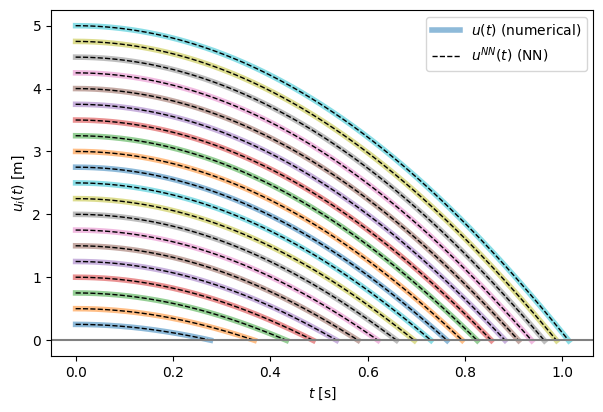

In [64]:
u_NN, R_NN = inverse_problem(solver_inverse.best_nets, t_inverse, u0, v0, tf)
t_plot, u_NN, R_NN = to_plot(t_inverse), to_plot(u_NN), to_plot(R_NN)

plt.figure(figsize=(7, 4.5))
for i in range(N):
    if i==0:
        plt.plot(numerical[i][0], numerical[i][1], color=f'C{i}', lw=4, alpha=0.5, label=f'$u(t)$ (numerical)')
        plt.plot(t_plot[i], u_NN[i], 'k--', lw=1, label=f'$u^{{NN}}(t)$ (NN)')
    else:
        plt.plot(numerical[i][0], numerical[i][1], color=f'C{i}', lw=4, alpha=0.5)
        plt.plot(t_plot[i], u_NN[i], 'k--', lw=1)
plt.legend()
plt.axhline(0, color='gray')
plt.xlabel('$t$ [s]')
plt.ylabel('$u_i(t)$ [m]')
plt.show()

#### Residuals of the ODE
At the best loss, for all the initial conditions.

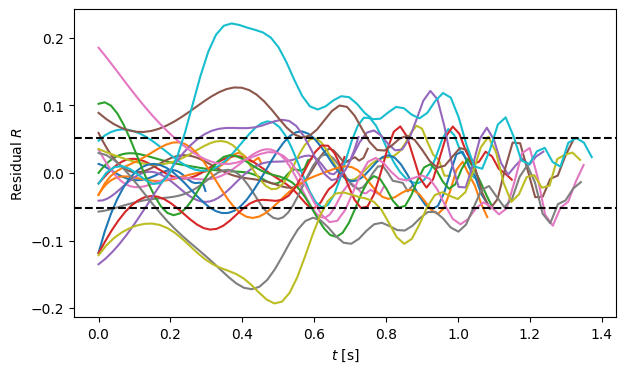

In [335]:
plt.figure(figsize=(7, 4))
for i in range(N):
    plt.plot(t_plot[i], R_NN[i], color=f'C{i}')
plt.axhline(np.sqrt(min(solver_inverse.loss_history)), color='k', linestyle='--')
plt.axhline(-np.sqrt(min(solver_inverse.loss_history)), color='k', linestyle='--')
plt.xlabel('$t$ [s]')
plt.ylabel('Residual $R$')
plt.show()

### Save the model (optional)

In [33]:
save_model(solver_inverse, 'results/inverse_problem.pt')

Model saved in results/inverse_problem.pt


## Things to try

- Change the potential in Section 1 to a non-linear one, e.g. $V(u) = g\,u + \tfrac{2}{3}u^3$ (so $\partial V/\partial u = g + 2u^2$), and check that the inverse problem recovers it.
- Raise the lowest initial height (e.g. `u0_data = np.linspace(1.0, 2.5, N)`). All the balls now cross the region close to the floor at high speed, so $t_f$ is barely sensitive to the potential there. How well is $V(u)$ recovered for $u < 1$?
- Change the number of data pairs $N$, or give the balls an initial velocity.